In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from google.colab import files
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

HO_TEN = "TRẦN THỊ MỸ DUNG"
MSSV = "6451071008"

def thong_tin(cau):
    print(f"Họ tên: {HO_TEN}")
    print(f"MSSV: {MSSV}")
    print(f"BÀI 2 (TRANG 18) - CÂU {cau}")
    print("-" * 50)

uploaded = files.upload()
file_name = next(iter(uploaded))
df = pd.read_csv(file_name, encoding="utf-8-sig")

df.columns = df.columns.str.strip()
df = df.rename(columns={
    "Genre": "Gender",
    "Annual Income (k$)": "Annual Income",
    "Annual Income (k $)": "Annual Income",
    "Spending Score (1-100)": "Spending Score",
    "Spending Score (1-100) ": "Spending Score"
})

required = ["Gender", "Age", "Annual Income", "Spending Score"]
missing = [col for col in required if col not in df.columns]

if missing:
    raise ValueError(
        f"Thiếu các cột: {missing}. "
        f"Cột thực tế: {df.columns.tolist()}"
    )

print("Upload thành công:", file_name)
print("Kích thước:", df.shape)
print("Các cột:", df.columns.tolist())
print(df.head().to_string())


Saving Mall_Customers.csv to Mall_Customers (1).csv
Upload thành công: Mall_Customers (1).csv
Kích thước: (200, 5)
Các cột: ['CustomerID', 'Gender', 'Age', 'Annual Income', 'Spending Score']
   CustomerID  Gender  Age  Annual Income  Spending Score
0           1    Male   19             15              39
1           2    Male   21             15              81
2           3  Female   20             16               6
3           4  Female   23             16              77
4           5  Female   31             17              40


In [14]:

# Câu 1: Thống kê dữ liệu và xử lý giá trị thiếu
thong_tin("1")

print("5 dòng đầu tiên:")
print(df.head().to_string())

print("\nKích thước dữ liệu:", df.shape)
print("\nThông tin dữ liệu:")
df.info()

print("\nThống kê mô tả:")
print(df.describe(include="all").to_string())

print("\nSố giá trị thiếu trước xử lý:")
print(df.isnull().sum())

for col in ["Age", "Annual Income", "Spending Score"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df[col] = df[col].fillna(df[col].median())

df["Gender"] = df["Gender"].replace(r"^\s*$", np.nan, regex=True)

if df["Gender"].isnull().any():
    df["Gender"] = df["Gender"].fillna(df["Gender"].mode()[0])

print("\nSố giá trị thiếu sau xử lý:")
print(df.isnull().sum())


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 2 (TRANG 18) - CÂU 1
--------------------------------------------------
5 dòng đầu tiên:
   CustomerID  Gender  Age  Annual Income  Spending Score
0           1    Male   19             15              39
1           2    Male   21             15              81
2           3  Female   20             16               6
3           4  Female   23             16              77
4           5  Female   31             17              40

Kích thước dữ liệu: (200, 5)

Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   CustomerID      200 non-null    int64 
 1   Gender          200 non-null    object
 2   Age             200 non-null    int64 
 3   Annual Income   200 non-null    int64 
 4   Spending Score  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Thốn

Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 2 (TRANG 18) - CÂU 2
--------------------------------------------------


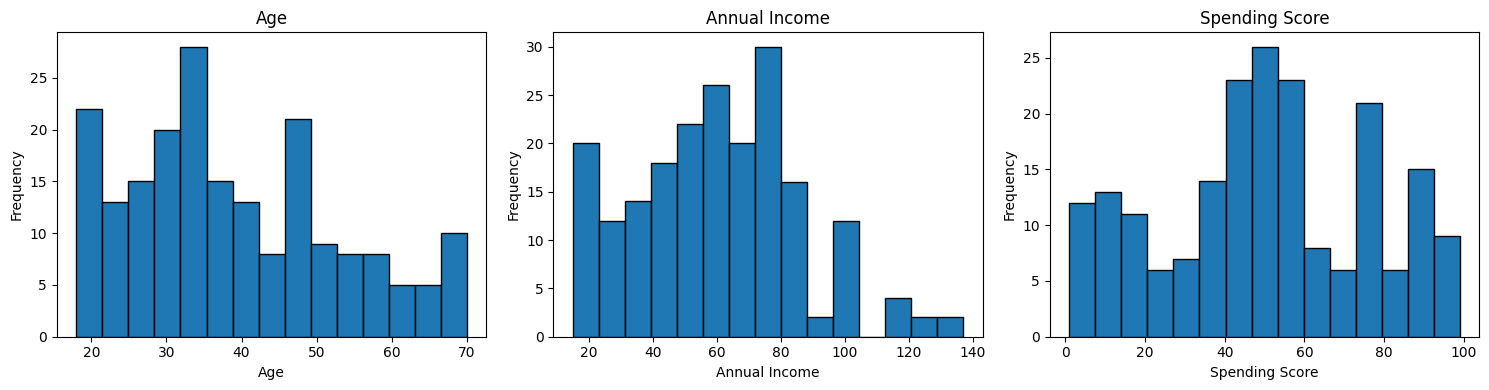

In [5]:

# Câu 2: Vẽ Histogram tuổi, thu nhập và điểm mua sắm
thong_tin("2")

columns = ["Age", "Annual Income", "Spending Score"]

plt.figure(figsize=(15, 4))

for i, col in enumerate(columns):
    plt.subplot(1, 3, i + 1)
    plt.hist(df[col], bins=15, edgecolor="black")
    plt.title(col)
    plt.xlabel(col)
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 2 (TRANG 18) - CÂU 3
--------------------------------------------------
Số khách hàng theo giới tính:
Gender
Female    112
Male       88
Name: count, dtype: int64


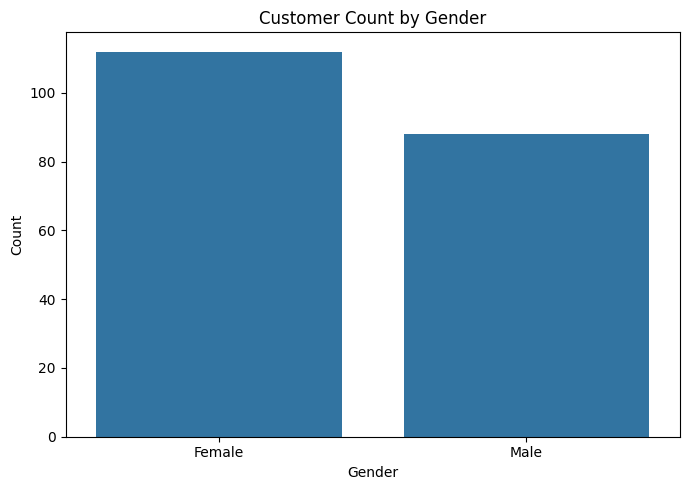

In [6]:

# Câu 3: Thống kê số khách hàng theo giới tính
thong_tin("3")

gender_counts = df["Gender"].value_counts()

print("Số khách hàng theo giới tính:")
print(gender_counts)

plt.figure(figsize=(7, 5))
sns.countplot(
    data=df,
    x="Gender",
    order=gender_counts.index
)

plt.title("Customer Count by Gender")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 2 (TRANG 18) - CÂU 4
--------------------------------------------------


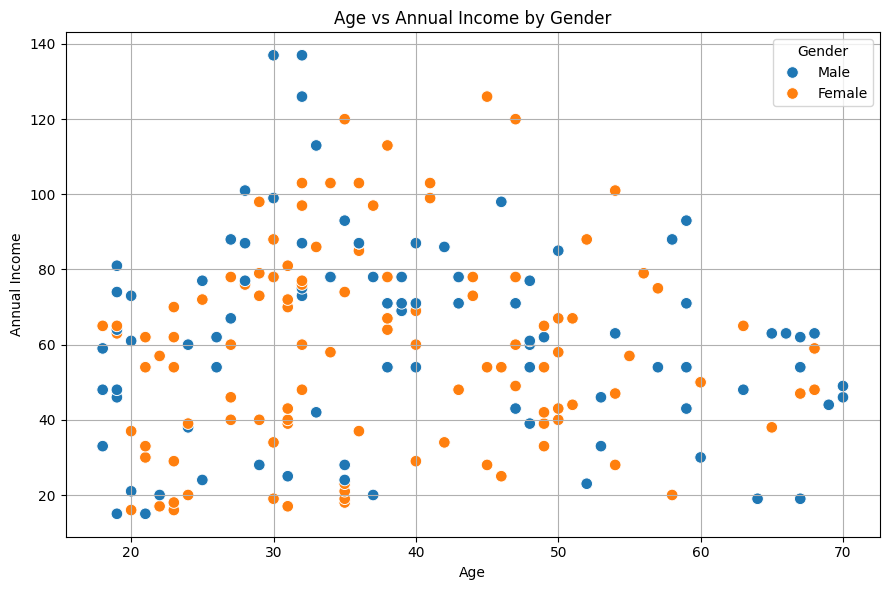

In [7]:

# Câu 4: Khảo sát tuổi và thu nhập theo giới tính
thong_tin("4")

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Age",
    y="Annual Income",
    hue="Gender",
    s=70
)

plt.title("Age vs Annual Income by Gender")
plt.xlabel("Age")
plt.ylabel("Annual Income")
plt.grid(True)
plt.tight_layout()
plt.show()


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 2 (TRANG 18) - CÂU 5
--------------------------------------------------


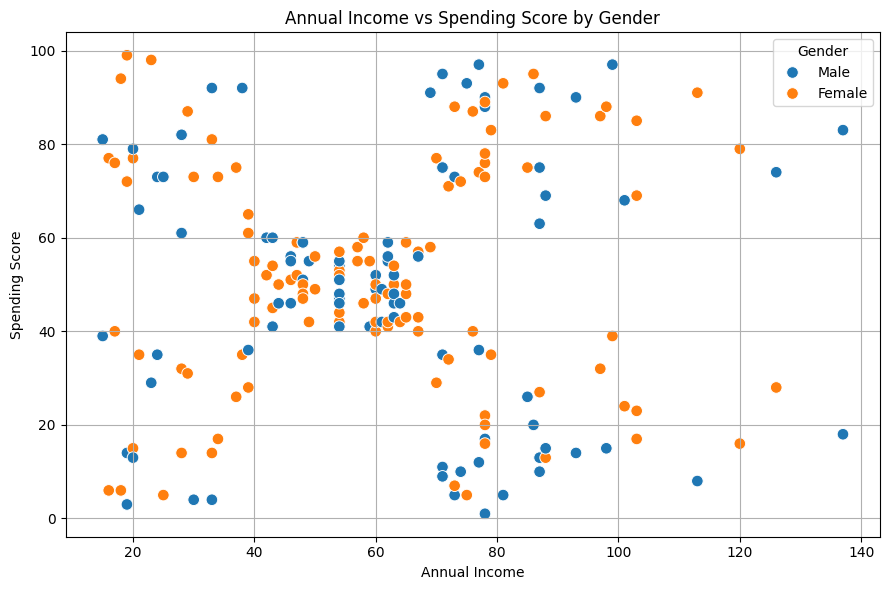

In [8]:

# Câu 5: Khảo sát thu nhập và điểm mua sắm theo giới tính
thong_tin("5")

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Annual Income",
    y="Spending Score",
    hue="Gender",
    s=70
)

plt.title("Annual Income vs Spending Score by Gender")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.grid(True)
plt.tight_layout()
plt.show()


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 2 (TRANG 18) - CÂU 6
--------------------------------------------------


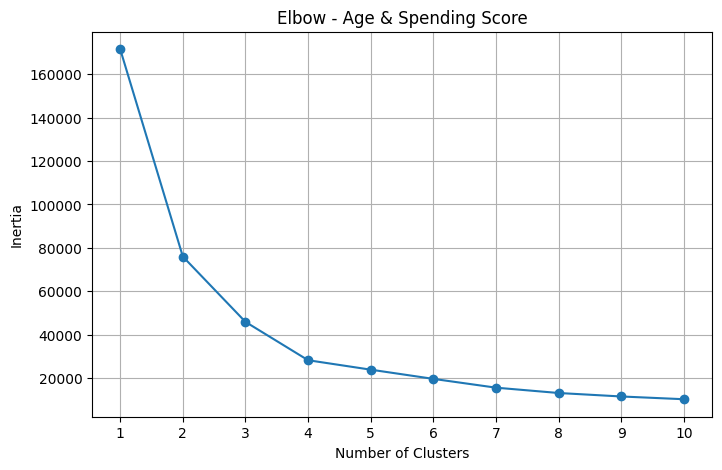

Số cụm đã chọn: 4

Tâm các cụm:
[[55.70833333 48.22916667]
 [30.1754386  82.35087719]
 [43.29166667 15.02083333]
 [27.61702128 49.14893617]]

Số khách hàng từng cụm:
0    48
1    57
2    48
3    47
Name: count, dtype: int64


In [9]:

# Câu 6: Xác định số cụm bằng Elbow và gom cụm K-Means
thong_tin("6")

X_age = df[["Age", "Spending Score"]].values

wss_age = []

for k in range(1, min(11, len(X_age) + 1)):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_age)
    wss_age.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(wss_age) + 1), wss_age, marker="o")
plt.title("Elbow - Age & Spending Score")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(range(1, len(wss_age) + 1))
plt.grid(True)
plt.show()

k_age = 4

km_age = KMeans(n_clusters=k_age, random_state=42, n_init=10)
labels_age = km_age.fit_predict(X_age)

print("Số cụm đã chọn:", k_age)
print("\nTâm các cụm:")
print(km_age.cluster_centers_)

print("\nSố khách hàng từng cụm:")
print(pd.Series(labels_age).value_counts().sort_index())


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 2 (TRANG 18) - CÂU 7
--------------------------------------------------


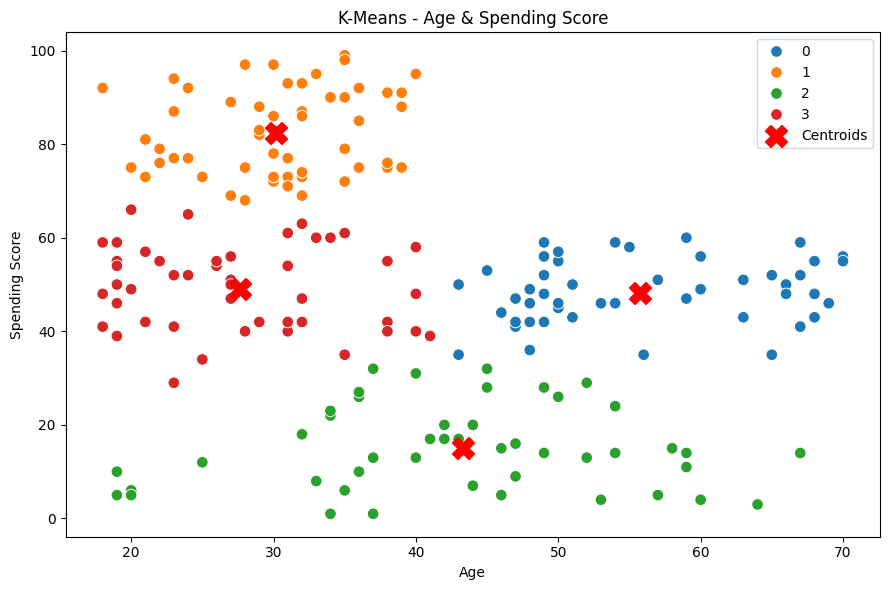

In [10]:

# Câu 7: Vẽ kết quả gom cụm khách hàng
thong_tin("7")

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_age[:, 0],
    y=X_age[:, 1],
    hue=labels_age,
    palette="tab10",
    s=70
)

centers = km_age.cluster_centers_

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    c="red",
    marker="X",
    s=250,
    label="Centroids"
)

plt.title("K-Means - Age & Spending Score")
plt.xlabel("Age")
plt.ylabel("Spending Score")
plt.legend()
plt.tight_layout()
plt.show()


In [11]:

# Câu 8: Đánh giá gom cụm bằng Silhouette Score
thong_tin("8")

score_age = silhouette_score(X_age, labels_age)

print("Số cụm:", k_age)
print(f"Silhouette Score: {score_age:.4f}")


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 2 (TRANG 18) - CÂU 8
--------------------------------------------------
Số cụm: 4
Silhouette Score: 0.4997


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 2 (TRANG 18) - CÂU 9 - Truong hop 1
--------------------------------------------------


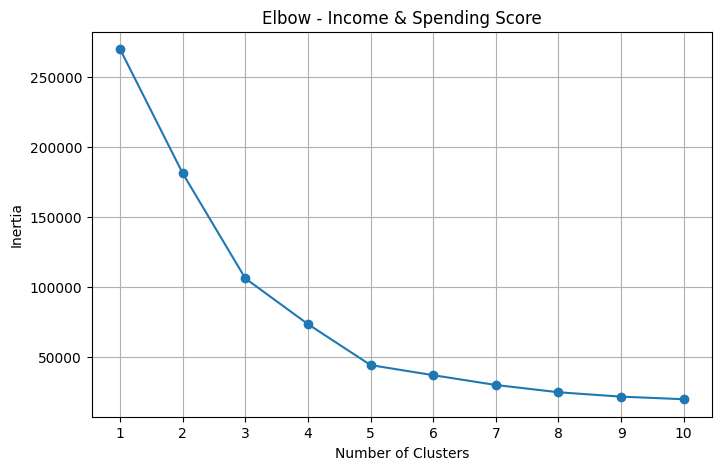

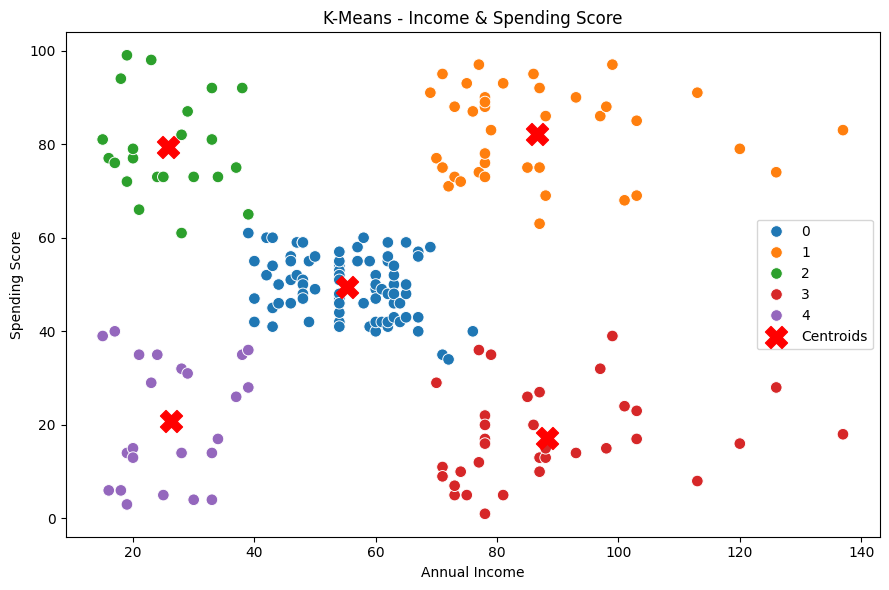

Số cụm: 5
Silhouette Score: 0.5539


In [12]:

# Câu 9: Gom cụm theo thu nhập và điểm mua sắm
thong_tin("9 - Truong hop 1")

X_income = df[["Annual Income", "Spending Score"]].values

wss_income = []

for k in range(1, min(11, len(X_income) + 1)):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_income)
    wss_income.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(wss_income) + 1), wss_income, marker="o")
plt.title("Elbow - Income & Spending Score")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(range(1, len(wss_income) + 1))
plt.grid(True)
plt.show()

k_income = 5

km_income = KMeans(n_clusters=k_income, random_state=42, n_init=10)
labels_income = km_income.fit_predict(X_income)

plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=X_income[:, 0],
    y=X_income[:, 1],
    hue=labels_income,
    palette="tab10",
    s=70
)

plt.scatter(
    km_income.cluster_centers_[:, 0],
    km_income.cluster_centers_[:, 1],
    c="red",
    marker="X",
    s=250,
    label="Centroids"
)

plt.title("K-Means - Income & Spending Score")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.legend()
plt.tight_layout()
plt.show()

score_income = silhouette_score(X_income, labels_income)

print("Số cụm:", k_income)
print(f"Silhouette Score: {score_income:.4f}")


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 2 (TRANG 18) - CÂU 9 - Truong hop 2
--------------------------------------------------


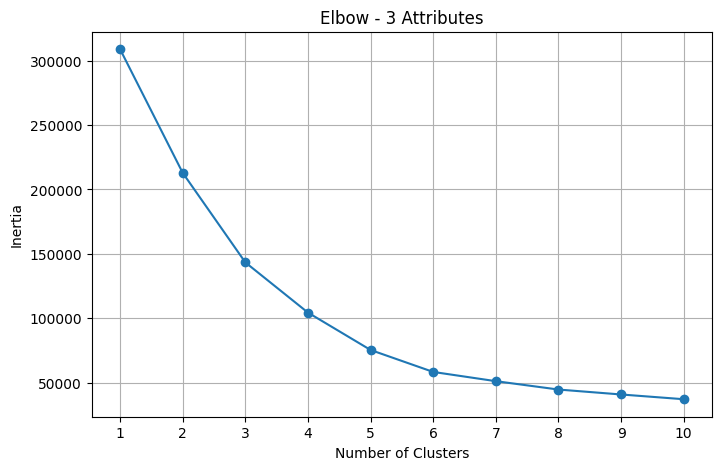

Số cụm: 5
Silhouette Score: 0.4443


In [13]:

# Câu 9: Gom cụm ba thuộc tính và biểu diễn bằng biểu đồ 3D
thong_tin("9 - Truong hop 2")

X_3d = df[["Age", "Annual Income", "Spending Score"]].values

wss_3d = []

for k in range(1, min(11, len(X_3d) + 1)):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_3d)
    wss_3d.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(wss_3d) + 1), wss_3d, marker="o")
plt.title("Elbow - 3 Attributes")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(range(1, len(wss_3d) + 1))
plt.grid(True)
plt.show()

k_3d = 5

km_3d = KMeans(n_clusters=k_3d, random_state=42, n_init=10)
labels_3d = km_3d.fit_predict(X_3d)

df_3d = df.copy()
df_3d["Cluster"] = labels_3d.astype(str)

fig = px.scatter_3d(
    df_3d,
    x="Age",
    y="Annual Income",
    z="Spending Score",
    color="Cluster",
    title="K-Means Clustering - 3D",
    opacity=0.8
)

fig.show()

score_3d = silhouette_score(X_3d, labels_3d)

print("Số cụm:", k_3d)
print(f"Silhouette Score: {score_3d:.4f}")
